# OpenAIRE Graph University Overview

This notebook fetches summary statistics per university using the [OpenAIRE Graph API](https://graph.openaire.eu/docs/apis/graph-api/). For every listed university we compare three perspectives:

- **A. Publications affiliated to the university** – filter on the OpenAIRE OpenORG identifier.
- **B. Publications collected by the main (CRIS) data source** – filter on the CRS/data source identifier.
- **C. Publications collected by the secondary repository** – filter on the repository identifier when available.

For each perspective we retrieve counts for funding/projects, data sources, and research products split into publications, datasets, software, and other research outputs. The notebook separates the data collection steps so that each can be re-run independently when debugging or iterating.


In [4]:
!pip install pandas matplotlib

## 1. Imports and reused constants


In [13]:

import csv
import time
from copy import deepcopy
from io import StringIO
from typing import Any, Dict, Optional

import pandas as pd
import requests
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.float_format", lambda value: f"{value:,.0f}")

BASE_URL = "https://api.openaire.eu/graph"
API_USER_AGENT = "OpenAIRE-tools overview-stats notebook"
API_PAUSE_SECONDS = 0.1  # throttle requests a bit to stay within rate limits

PRODUCT_TYPE_LABELS = {
    "publication": "Publications",
    "dataset": "Research data",
    "software": "Research software",
    "other": "Other research products",
}

METRIC_ORDER = [
    "Funding / Projects",
    "Data sources",
    *PRODUCT_TYPE_LABELS.values(),
]

COMPARISON_LONG_PATH = "comparison_long.csv"
COMPARISON_PIVOT_PATH = "comparison_pivot.csv"


## 2. Parse the university reference table
The raw table below mirrors the values supplied in the request. We reshape it into a structured list so that the rest of the notebook can iterate over the entries.


In [14]:

TABLE_PATH = "aurora-sources.tsv"


def load_university_table(path: str) -> pd.DataFrame:
    """Load the Aurora TSV table and normalise empty values to blanks."""
    df = pd.read_csv(path, sep="	", dtype=str, keep_default_na=False)
    return df.fillna("")


def _pick(row: pd.Series, *columns: str) -> str:
    for column in columns:
        if column not in row:
            continue
        value = row[column]
        if isinstance(value, str):
            value = value.strip()
        if value:
            return value
    return ""


def parse_university_rows(df: pd.DataFrame) -> list[dict[str, Optional[str]]]:
    parsed: list[dict[str, Optional[str]]] = []
    for _, row in df.iterrows():
        name = _pick(row, "University")
        if not name or name.lower() == "aurora":
            continue

        entry = {
            "name": name,
            "aurora2030_participant": _pick(row, "Full Aurora2030 participant") or None,
            "rpo_monitor_opt_in": _pick(row, "opts in for individual RPO Monitor") or None,
            "ror": _pick(row, "ROR ID LINK") or None,
            "openorg_id": _pick(row, "OpenAIRE OpenORG ID", "OpenAIRE OpenORG ID LINK") or None,
            "main_datasource_id": _pick(row, "OpenAIRE Data Source ID (Main/CRIS)", "OpenAIRE Data Source ID (Main/CRIS) LINK") or None,
            "secondary_datasource_id": _pick(row, "OpenAIRE Data Source (Secondary/Repository)", "OpenAIRE Data Source (Secondary/Repository) LINK") or None,
        }

        if entry["main_datasource_id"] and entry["main_datasource_id"].startswith("opendoar"):
            if not entry["secondary_datasource_id"]:
                entry["secondary_datasource_id"] = entry["main_datasource_id"]
                entry["main_datasource_id"] = None

        parsed.append(entry)

    return parsed


table_df = load_university_table(TABLE_PATH)
universities = parse_university_rows(table_df)
print(f"Parsed {len(universities)} universities from the reference table (loaded from {TABLE_PATH}).")
universities_df = pd.DataFrame(universities)
universities_df


Parsed 14 universities from the reference table (loaded from aurora-sources.tsv).


,name,aurora2030_participant,rpo_monitor_opt_in,ror,openorg_id,main_datasource_id,secondary_datasource_id
0,Vrije Universiteit Amsterdam,yes,yes,008xxew50,openorgs____::1624ff7c01bb641b91f4518539a0c28a,eurocrisdris::1d6d17347c8e4a306c1173fd700c2f45,None
1,Uni Duisburg-Essen,yes,yes,04mz5ra38,openorgs____::0b0102bae51f4f4ef5ba57fbe1523b92,openaire____::9fd684e0c0334260671bad2c21a8d09e,opendoar____::c15da1f2b5e5ed6e6837a3802f0d1593
2,Uni Napoli Federico II,yes,yes,05290cv24,openorgs____::eb0669daa9efeb898a3090d8aac7c953,eurocrisdris::2a2cfa6d4b4188dfbaee90f0e2e43a88,opendoar____::37a749d808e46495a8da1e5352d03cae
3,Uni of Iceland,yes,yes,01db6h964,openorgs____::cdda7cfe17c89eb50628ec2eb1f8acd2,eurocrisdris::b6bef57699b4935082659a3de52ff33c,opendoar____::87ae6fb631f7c8a627e8e28785d9992d
4,Uni of Innsbruck,yes,no,054pv6659,openorgs____::f7cfcc98245e22c7d6e321cde930e746,eurocrisdris::2abda3cef483af299821160069bf7f94,None
5,Uni Palacký Olomouc,yes,no,04qxnmv42,openorgs____::039192f47416999e406a6b57da19beeb,None,opendoar____::c974b58d1b0df79a20503c23e67cea69
6,Uni Rovira i Virgili,yes,yes,00g5sqv46,openorgs____::eb391317ed0dc684aa81ac16265de041,eurocrisdris::509817a6d8bce5115d99e4a802c23313,opendoar____::0b6ace9e8971cf36f1782aa982a708db
7,Copenhagen Business School,yes,yes,04sppb023,openorgs____::0a45de396fc864dc70d42d13f4e786e1,eurocrisdris::68f3b9dd626a93303aae01f9ebe82e1c,opendoar____::289dff07669d7a23de0ef88d2f7129e7
8,Uni Paris-Est Créteil,yes,yes,05ggc9x40,openorgs____::d1f5d132714edad4a952e0414fc3c94b,None,opendoar____::8640ff6ca914c9855203ac93e4c05119
9,University of Minnesota,no,no,017zqws13,dedup_wf_002::3149a35e137096edddfa52287294de51,None,None


## 3. Helper functions for the Graph API
These functions wrap the REST requests and centralise filter construction per scenario. Each call prints nothing by default so we can reuse them freely in later cells.


In [7]:

SCENARIO_DEFS = [
    {
        "key": "organization",
        "label": "A. OpenORG affiliation",
        "id_field": "openorg_id",
        "description": "Publications affiliated to the university (OpenAIRE OpenORG ID)",
    },
    {
        "key": "main_datasource",
        "label": "B. Main/CRIS data source",
        "id_field": "main_datasource_id",
        "description": "Publications collected from the main CRIS data source",
    },
    {
        "key": "secondary_datasource",
        "label": "C. Secondary repository",
        "id_field": "secondary_datasource_id",
        "description": "Publications collected from the secondary / repository data source",
    },
]

FILTER_BUILDERS = {
    "organization": lambda entity_id: {
        "projects": {"relOrganizationId": entity_id},
        "dataSources": {"relOrganizationId": entity_id},
        "researchProducts": {"relOrganizationId": entity_id},
    },
    "main_datasource": lambda entity_id: {
        "projects": {"relCollectedFromDatasourceId": entity_id},
        "dataSources": {"id": entity_id},
        "researchProducts": {"relCollectedFromDatasourceId": entity_id},
    },
    "secondary_datasource": lambda entity_id: {
        "projects": {"relCollectedFromDatasourceId": entity_id},
        "dataSources": {"id": entity_id},
        "researchProducts": {"relCollectedFromDatasourceId": entity_id},
    },
}

EMPTY_METRICS = {metric: None for metric in METRIC_ORDER}


def call_graph_api(path: str, params: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    """Invoke the OpenAIRE Graph API and return the decoded JSON payload."""
    url = f"{BASE_URL}{path}"
    effective_params = dict(params or {})
    effective_params.setdefault("page", 1)
    effective_params.setdefault("pageSize", 1)

    response = requests.get(
        url,
        params=effective_params,
        headers={"User-Agent": API_USER_AGENT},
        timeout=60,
    )
    response.raise_for_status()
    time.sleep(API_PAUSE_SECONDS)
    return response.json()


def fetch_num_found(path: str, params: Dict[str, Any]) -> Optional[int]:
    """Return the total number of matching records for the supplied endpoint."""
    payload = call_graph_api(path, params)
    header = payload.get("header", {})
    num_found = header.get("numFound")
    return int(num_found) if num_found is not None else None


def build_filters(scenario_key: str, entity_id: str) -> Dict[str, Dict[str, Any]]:
    builder = FILTER_BUILDERS[scenario_key]
    return {name: dict(filters) for name, filters in builder(entity_id).items()}


def collect_metrics(scenario_key: str, entity_id: Optional[str]) -> Dict[str, Optional[int]]:
    if not entity_id:
        return deepcopy(EMPTY_METRICS)

    filters = build_filters(scenario_key, entity_id)
    results: Dict[str, Optional[int]] = {}

    results["Funding / Projects"] = fetch_num_found("/v1/projects", filters["projects"])
    results["Data sources"] = fetch_num_found("/v1/dataSources", filters["dataSources"])

    for rp_type, label in PRODUCT_TYPE_LABELS.items():
        rp_params = dict(filters["researchProducts"], type=rp_type)
        results[label] = fetch_num_found("/v2/researchProducts", rp_params)

    return results


## 4. Sanity check on a single university
Run a quick test so we know the API access works before looping over the full list.


In [8]:

sample_university = universities[0]
print(f"Sample university: {sample_university['name']}")
for scenario in SCENARIO_DEFS:
    identifier = sample_university.get(scenario["id_field"])
    metrics = collect_metrics(scenario["key"], identifier)
    print(f"  {scenario['label']} ({identifier}):")
    for metric in METRIC_ORDER:
        print(f"    - {metric}: {metrics.get(metric)}")


Sample university: Vrije Universiteit Amsterdam
  A. OpenORG affiliation (openorgs____::1624ff7c01bb641b91f4518539a0c28a):
    - Funding / Projects: 1893
    - Data sources: 5
    - Publications: 243536
    - Research data: 14022
    - Research software: 471
    - Other research products: 3463
  B. Main/CRIS data source (eurocrisdris::1d6d17347c8e4a306c1173fd700c2f45):
    - Funding / Projects: 0
    - Data sources: 1
    - Publications: 183415
    - Research data: 3122
    - Research software: 15
    - Other research products: 3080
  C. Secondary repository (None):
    - Funding / Projects: None
    - Data sources: None
    - Publications: None
    - Research data: None
    - Research software: None
    - Other research products: None


## 5. Fetch metrics for all universities
This cell iterates over every university and prints intermediate summaries for transparency during execution.


In [9]:

aggregated_results: list[dict[str, Any]] = []

for university in universities:
    uni_entry = {
        "info": university,
        "scenarios": {},
    }
    print(f"\n=== {university['name']} ===")
    for scenario in SCENARIO_DEFS:
        identifier = university.get(scenario["id_field"])
        metrics = collect_metrics(scenario["key"], identifier)
        uni_entry["scenarios"][scenario["key"]] = metrics

        label = scenario["label"]
        identifier_display = identifier if identifier else "no identifier provided"
        print(f"{label} ({identifier_display}):")
        for metric in METRIC_ORDER:
            print(f"  {metric}: {metrics.get(metric)}")
    aggregated_results.append(uni_entry)

print("\nCompleted data collection for all universities.")



=== Vrije Universiteit Amsterdam ===
A. OpenORG affiliation (openorgs____::1624ff7c01bb641b91f4518539a0c28a):
  Funding / Projects: 1893
  Data sources: 5
  Publications: 243536
  Research data: 14022
  Research software: 471
  Other research products: 3463
B. Main/CRIS data source (eurocrisdris::1d6d17347c8e4a306c1173fd700c2f45):
  Funding / Projects: 0
  Data sources: 1
  Publications: 183415
  Research data: 3122
  Research software: 15
  Other research products: 3080
C. Secondary repository (no identifier provided):
  Funding / Projects: None
  Data sources: None
  Publications: None
  Research data: None
  Research software: None
  Other research products: None

=== Uni Duisburg-Essen ===
A. OpenORG affiliation (openorgs____::0b0102bae51f4f4ef5ba57fbe1523b92):
  Funding / Projects: 202
  Data sources: 3
  Publications: 83221
  Research data: 1388
  Research software: 298
  Other research products: 326
B. Main/CRIS data source (openaire____::9fd684e0c0334260671bad2c21a8d09e):
  Fu

## 6. Assemble and save the comparison table
We reshape the collected metrics into both a long format and a pivoted table, then cache them on disk for reuse.


In [10]:
records: list[dict[str, Any]] = []
for entry in aggregated_results:
    base = entry["info"]
    for scenario in SCENARIO_DEFS:
        metrics = entry["scenarios"].get(scenario["key"], {})
        for metric in METRIC_ORDER:
            records.append(
                {
                    "University": base["name"],
                    "ROR": base.get("ror"),
                    "Scenario": scenario["label"],
                    "Metric": metric,
                    "Count": metrics.get(metric),
                }
            )

comparison_df = pd.DataFrame(records)
comparison_pivot = (
    comparison_df.pivot_table(
        index=["University", "ROR"],
        columns=["Scenario", "Metric"],
        values="Count",
    )
    .sort_index(axis=1, level=0)
    .astype("Int64")
)

comparison_df.to_csv(COMPARISON_LONG_PATH, index=False)
comparison_pivot.to_csv(COMPARISON_PIVOT_PATH)
print(f"Saved long-format table to {COMPARISON_LONG_PATH}")
print(f"Saved pivot table to {COMPARISON_PIVOT_PATH}")
comparison_pivot


Saved long-format table to comparison_long.csv
Saved pivot table to comparison_pivot.csv


Scenario                                            A. OpenORG affiliation  \
Metric                                                        Data sources   
University                                ROR                                
Copenhagen Business School                04sppb023                      6   
South-West University Neofit Rilski       002wcjr61                      2   
Uni Duisburg-Essen                        04mz5ra38                      3   
Uni Napoli Federico II                    05290cv24                     13   
Uni Palacký Olomouc                       04qxnmv42                     11   
Uni Paris-Est Créteil                     05ggc9x40                      1   
Uni Rovira i Virgili                      00g5sqv46                     10   
Uni of Iceland                            01db6h964                      4   
Uni of Innsbruck                          054pv6659                      4   
University of Minnesota                   017zqws13                      0   
University of Tetova                      01e4kx996                      0   
V. N. Karazin Kharkiv National University 03ftejk10                      0   
Vrije Universiteit Amsterdam              008xxew50                      5   

Scenario                                                                \
Metric                                              Funding / Projects   
University                                ROR                            
Copenhagen Business School                04sppb023                121   
South-West University Neofit Rilski       002wcjr61                 24   
Uni Duisburg-Essen                        04mz5ra38                202   
Uni Napoli Federico II                    05290cv24                416   
Uni Palacký Olomouc                       04qxnmv42                153   
Uni Paris-Est Créteil                     05ggc9x40                174   
Uni Rovira i Virgili                      00g5sqv46                216   
Uni of Iceland                            01db6h964                252   
Uni of Innsbruck                          054pv6659                331   
University of Minnesota                   017zqws13                  0   
University of Tetova                      01e4kx996                  2   
V. N. Karazin Kharkiv National University 03ftejk10                  0   
Vrije Universiteit Amsterdam              008xxew50               1893   

Scenario                                                                     \
Metric                                              Other research products   
University                                ROR                                 
Copenhagen Business School                04sppb023                    3144   
South-West University Neofit Rilski       002wcjr61                      33   
Uni Duisburg-Essen                        04mz5ra38                     326   
Uni Napoli Federico II                    05290cv24                   60835   
Uni Palacký Olomouc                       04qxnmv42                     416   
Uni Paris-Est Créteil                     05ggc9x40                    1617   
Uni Rovira i Virgili                      00g5sqv46                   17044   
Uni of Iceland                            01db6h964                     162   
Uni of Innsbruck                          054pv6659                    1218   
University of Minnesota                   017zqws13                       0   
University of Tetova                      01e4kx996                       8   
V. N. Karazin Kharkiv National University 03ftejk10                       0   
Vrije Universiteit Amsterdam              008xxew50                    3463   

Scenario                                                          \
Metric                                              Publications   
University                                ROR                      
Copenhagen Business School                04sppb023        13395   
South-West University Neofit 

## 7. Reload saved comparison tables
Reload the cached CSV files so downstream steps can run without recomputing the API queries.


In [11]:
comparison_df = pd.read_csv(COMPARISON_LONG_PATH)
if "Count" in comparison_df.columns:
    comparison_df["Count"] = comparison_df["Count"].astype("Int64")

comparison_pivot = pd.read_csv(
    COMPARISON_PIVOT_PATH,
    header=[0, 1],
    index_col=[0, 1],
)
comparison_pivot.columns = pd.MultiIndex.from_tuples(comparison_pivot.columns)
comparison_pivot = comparison_pivot.astype("Int64")
print(f"Reloaded tables from {COMPARISON_LONG_PATH} and {COMPARISON_PIVOT_PATH}")
comparison_pivot


Reloaded tables from comparison_long.csv and comparison_pivot.csv


A. OpenORG affiliation  \
                                                              Data sources   
University                                ROR                                
Copenhagen Business School                04sppb023                      6   
South-West University Neofit Rilski       002wcjr61                      2   
Uni Duisburg-Essen                        04mz5ra38                      3   
Uni Napoli Federico II                    05290cv24                     13   
Uni Palacký Olomouc                       04qxnmv42                     11   
Uni Paris-Est Créteil                     05ggc9x40                      1   
Uni Rovira i Virgili                      00g5sqv46                     10   
Uni of Iceland                            01db6h964                      4   
Uni of Innsbruck                          054pv6659                      4   
University of Minnesota                   017zqws13                      0   
University of Tetova                      01e4kx996                      0   
V. N. Karazin Kharkiv National University 03ftejk10                      0   
Vrije Universiteit Amsterdam              008xxew50                      5   

                                                                        \
                                                    Funding / Projects   
University                                ROR                            
Copenhagen Business School                04sppb023                121   
South-West University Neofit Rilski       002wcjr61                 24   
Uni Duisburg-Essen                        04mz5ra38                202   
Uni Napoli Federico II                    05290cv24                416   
Uni Palacký Olomouc                       04qxnmv42                153   
Uni Paris-Est Créteil                     05ggc9x40                174   
Uni Rovira i Virgili                      00g5sqv46                216   
Uni of Iceland                            01db6h964                252   
Uni of Innsbruck                          054pv6659                331   
University of Minnesota                   017zqws13                  0   
University of Tetova                      01e4kx996                  2   
V. N. Karazin Kharkiv National University 03ftejk10                  0   
Vrije Universiteit Amsterdam              008xxew50               1893   

                                                                             \
                                                    Other research products   
University                                ROR                                 
Copenhagen Business School                04sppb023                    3144   
South-West University Neofit Rilski       002wcjr61                      33   
Uni Duisburg-Essen                        04mz5ra38                     326   
Uni Napoli Federico II                    05290cv24                   60835   
Uni Palacký Olomouc                       04qxnmv42                     416   
Uni Paris-Est Créteil                     05ggc9x40                    1617   
Uni Rovira i Virgili                      00g5sqv46                   17044   
Uni of Iceland                            01db6h964                     162   
Uni of Innsbruck                          054pv6659                    1218   
University of Minnesota                   017zqws13                       0   
University of Tetova                      01e4kx996                       8   
V. N. Karazin Kharkiv National University 03ftejk10                       0   
Vrije Universiteit Amsterdam              008xxew50                    3463   

                                                                  \
                                                    Publications   
University                                ROR                      
Copenhagen Business School                04sppb023        13395   
South-West University Neofit Rilski       002wcjr61         2943   
Uni Duisburg-

## 8. Visualising publication counts
The chart below compares publication totals by affiliation and harvesting source. Missing bars indicate that the corresponding source does not currently expose publications in the OpenAIRE Graph.


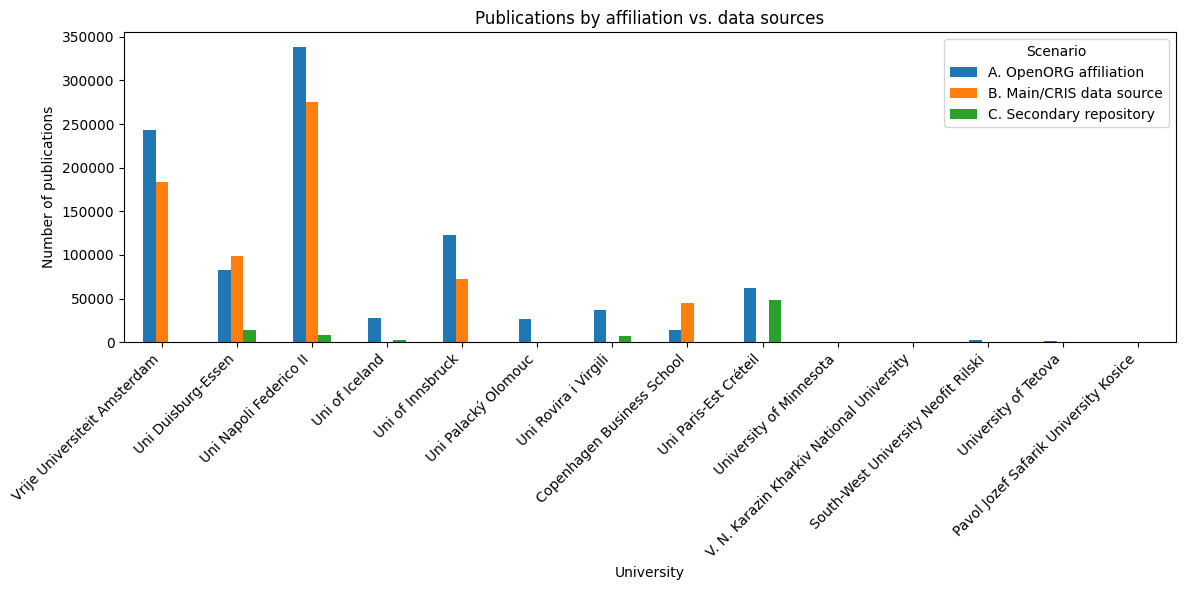

Note: Missing bars indicate that the source may not be connected to OpenAIRE or does not expose publications.

Universities with a CRIS data source but no publications retrieved from it:
- Uni of Iceland
- Uni Rovira i Virgili


In [15]:
publication_df = comparison_df[comparison_df["Metric"] == "Publications"].copy()
wide_publications = (
    publication_df.pivot(index="University", columns="Scenario", values="Count")
    .reindex(universities_df["name"].tolist())
)

fig, ax = plt.subplots(figsize=(12, 6))
wide_publications.plot(kind="bar", ax=ax)
ax.set_xlabel("University")
ax.set_ylabel("Number of publications")
ax.set_title("Publications by affiliation vs. data sources")
ax.legend(title="Scenario")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Note: Missing bars indicate that the source may not be connected to OpenAIRE or does not expose publications.")
main_datasource_label = next(
    scenario["label"]
    for scenario in SCENARIO_DEFS
    if scenario["key"] == "main_datasource"
)
if main_datasource_label not in wide_publications.columns:
    print("\nNo publication data available for the CRIS data source scenario.")
else:
    main_source_counts = wide_publications[main_datasource_label]
    has_main_datasource = universities_df["main_datasource_id"].fillna("").str.strip() != ""
    main_source_publications = universities_df["name"].map(main_source_counts)
    no_publications_mask = main_source_publications.isna() | (main_source_publications == 0)
    no_publications_cris = universities_df.loc[has_main_datasource & no_publications_mask, "name"].tolist()
    if no_publications_cris:
        print("\nUniversities with a CRIS data source but no publications retrieved from it:")
        for name in no_publications_cris:
            print(f"- {name}")
    else:
        print("\nAll CRIS-connected universities have publications retrieved from that data source.")


## 9. Notes and follow-ups
- A missing identifier (OpenORG or data source) results in `NA` counts for that scenario.
- Some organizations without a dedicated CRIS only contribute repository records, so their main data source column remains empty.
- Consider repeating the collection with date filters (e.g. recent years) or cursor-based pagination if you need to validate the totals beyond the `numFound` figures.
